In [63]:
%pylab inline
import gc
import math
import fitsio
import anautil
import treecorr
import numpy as np
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii
import matplotlib.lines as mlines
ver0='_bin1cut'
ver='_bin2dp'

Populating the interactive namespace from numpy and matplotlib


In [64]:
cd /work/xiangchong.li/work/cosmicShear/mockana

/work/xiangchong.li/work/cosmicShear/mockana


# index

This notebook serves to generate two-point correlation functions from halofit model

+ Plot the correlation functions with different n(z)
+ Make correlation function file for cosmosis

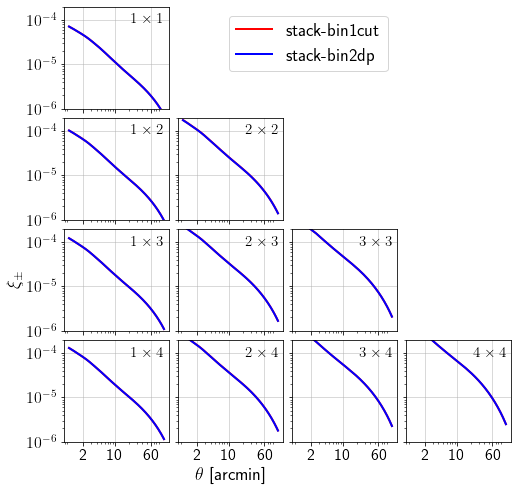

In [65]:
nzs=4
plt.close()
fig = plt.figure(figsize=(8,8))
for i in range(nzs):
    for j in range(i,nzs):
        ax = plt.subplot2grid((8, 8), (j*2, i*2), colspan=2,rowspan=2)
        ax.set_ylim(2e-6,2e-4)
        ax.set_title(r'$%d \times %d$' %(i+1,j+1),fontsize=15,y=1.0, pad=-15,x=0.8)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.grid()
        if i!=0:
            #ax.get_yaxis().set_visible(False)
            ax.set_yticks((1e-6,1e-5,1e-4))
            ax.set_yticklabels(('','',''))
            #ax.set_yticklabels(('$10^{-5}$','$10^{-4}$'))
        else:
            ax.set_yticks((1e-6,1e-5,1e-4))
        if j!=nzs-1:
            #ax.get_xaxis().set_visible(False)
            ax.set_xticks((2,10,60))
            ax.set_xticklabels(('','',''))
        else:
            ax.set_xticks((2,10,60))
            ax.set_xticklabels(('2','10','60'))
        if i==0 and j==2:
            ax.set_ylabel(r'$\xi_{\pm}$')
        if j==nzs-1 and i==1:
            ax.set_xlabel(r'$\theta$ [arcmin]')
        
        Dir='mock/meadcb1%s/' %ver0
        theta=np.loadtxt(os.path.join(Dir,'shear_xi_plus/theta.txt'))/np.pi*180.*60.
        xi1=np.loadtxt(os.path.join(Dir,'shear_xi_plus/bin_%d_%d.txt' %(j+1,i+1)))
        msk=(theta>1.)&(theta<120)
        ax.plot(theta[msk],xi1[msk],color='red')

        Dir='mock/meadcb1%s/' %ver
        theta=np.loadtxt(os.path.join(Dir,'shear_xi_plus/theta.txt'))/np.pi*180.*60.
        xi1cut=np.loadtxt(os.path.join(Dir,'shear_xi_plus/bin_%d_%d.txt' %(j+1,i+1)))
        msk=(theta>1.)&(theta<120)
        ax.plot(theta[msk],xi1cut[msk],color='blue')
ax = plt.subplot2grid((8, 8), (0*2, 2*2), colspan=2,rowspan=2)
ax.set_axis_off()
leg1 = mlines.Line2D([], [], color='red', ls='-',label='stack%s' %ver0.replace('_','-'))
leg2 = mlines.Line2D([], [], color='blue', ls='-',label='stack%s' %ver.replace('_','-'))
ll=ax.legend(handles=[leg1,leg2],loc='upper right',fontsize=18)

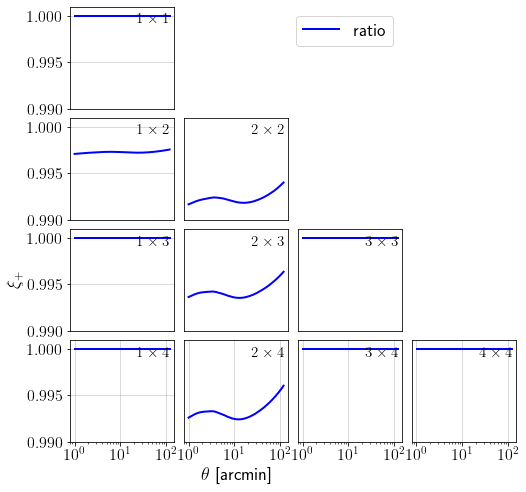

In [69]:
nzs=4
plt.close()
fig = plt.figure(figsize=(8,8))
for i in range(nzs):
    for j in range(i,nzs):
        ax = plt.subplot2grid((8, 8), (j*2, i*2), colspan=2,rowspan=2)
        ax.set_ylim(0.99,1.001)
        #ax.set_yscale('log')
        ax.set_title(r'$%d \times %d$' %(i+1,j+1),fontsize=15,y=1.0, pad=-15,x=0.8)
        ax.set_xscale('log')
        ax.grid()
        if i!=0:
            ax.get_yaxis().set_visible(False)
        if j!=nzs-1:
            ax.get_xaxis().set_visible(False)
            
        if i==0 and j==2:
            ax.set_ylabel(r'$\xi_{+}$')
        if j==nzs-1 and i==1:
            ax.set_xlabel(r'$\theta$ [arcmin]')
        
        Dir='mock/meadcb1%s/' %ver0
        theta=np.loadtxt(os.path.join(Dir,'shear_xi_plus/theta.txt'))/np.pi*180.*60.
        xi1=np.loadtxt(os.path.join(Dir,'shear_xi_plus/bin_%d_%d.txt' %(j+1,i+1)))
        msk=(theta>1.)&(theta<120)
        Dir='mock/meadcb1%s/' %ver
        theta=np.loadtxt(os.path.join(Dir,'shear_xi_plus/theta.txt'))/np.pi*180.*60.
        xi1cut=np.loadtxt(os.path.join(Dir,'shear_xi_plus/bin_%d_%d.txt' %(j+1,i+1)))
        msk=(theta>1.)&(theta<120)
        ax.plot(theta[msk],xi1cut[msk]/xi1[msk],color='blue')
ax = plt.subplot2grid((8, 8), (0*2, 2*2), colspan=2,rowspan=2)
ax.set_axis_off()
leg2 = mlines.Line2D([], [], color='blue', ls='-',label='ratio')
ll=ax.legend(handles=[leg2],loc='upper right',fontsize=18)

In [59]:
#ver='_iabias'
ver='_bin1cut'
Dir='mock/meadcb1%s/' %ver
ofname='mock/meadcb1%s.fits' %ver
cor   =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
logrIn=cor.logr
out=anautil.make_csdata_hdulist(Dir,logrIn)
out.writeto(ofname,overwrite=True)

In [5]:
old=pyfits.open(ofname+'.old')
assert np.all(out[1].data==old[1].data)
assert np.all(out[2].data==old[2].data)
assert np.all(out[3].data==old[3].data)
assert np.all(out[1].header==old[1].header)
assert np.all(out[2].header==old[2].header)
assert np.all(out[3].header==old[3].header)

In [42]:
import twopoint
T1 = twopoint.TwoPointFile.from_fits('mock/meadcb1.fits')
T1.plots(root='mock')